## Research questions
- Q1 Do sex and smoking status matter?
- Q2 How does the tip depend on the bill? Is generosity constant across bill sizes?
- Q3 Does the day or time matter?

## 1. Data overview and quality

In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
df_tips = sns.load_dataset("tips")
df_tips

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [3]:
df_tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [4]:
df_tips.info()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [5]:
df_tips.describe(include="all")

,total_bill,tip,sex,smoker,day,time,size
count,244.000000,244.000000,244,244,244,244,244.000000
unique,NaN,NaN,2,2,4,2,NaN
top,NaN,NaN,Male,No,Sat,Dinner,NaN
freq,NaN,NaN,157,151,87,176,NaN
mean,19.785943,2.998279,NaN,NaN,NaN,NaN,2.569672
std,8.902412,1.383638,NaN,NaN,NaN,NaN,0.951100
min,3.070000,1.000000,NaN,NaN,NaN,NaN,1.000000
25%,13.347500,2.000000,NaN,NaN,NaN,NaN,2.000000
50%,17.795000,2.900000,NaN,NaN,NaN,NaN,2.000000
75%,24.127500,3.562500,NaN,NaN,NaN,NaN,3.000000


### Duplicates

In [6]:
df_tips.duplicated().sum()

np.int64(1)

In [7]:
df_tips[df_tips.duplicated(keep=False)]

,total_bill,tip,sex,smoker,day,time,size
198,13.0,2.0,Female,Yes,Thur,Lunch,2
202,13.0,2.0,Female,Yes,Thur,Lunch,2


Not a duplicate, but two similar orders: there is no order ID to confirm it, so the row is kept.

### Missing values and categories

In [8]:
df_tips.isnull().sum()

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

In [9]:
for col in df_tips.select_dtypes(include="category"):
    print(f"{col}: {df_tips[col].unique().tolist()}")

print(df_tips[["total_bill", "tip", "size"]].nunique())

sex: ['Female', 'Male']
smoker: ['No', 'Yes']
day: ['Sun', 'Sat', 'Thur', 'Fri']
time: ['Dinner', 'Lunch']
total_bill    229
tip           123
size            6
dtype: int64


## 2. Distributions

In [10]:
df_tips["tip_pct"] = df_tips["tip"] / df_tips["total_bill"] * 100

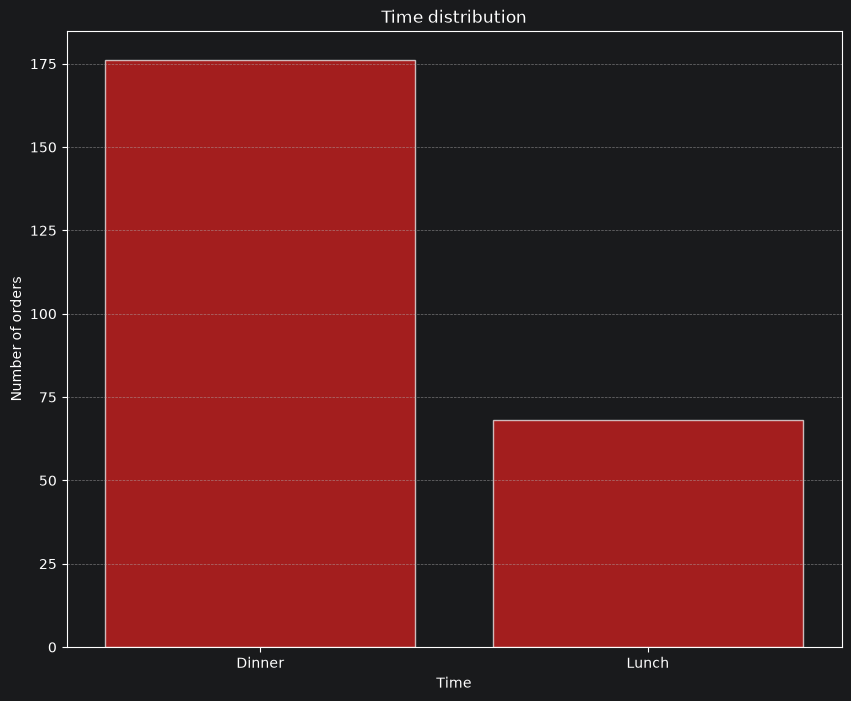

In [11]:
plt.figure(figsize=(10,8))

sns.countplot(
    data=df_tips,
    x="time",
    order=df_tips["time"].value_counts().index,
    edgecolor = "white",
    color = "red",
    alpha = 0.7
)

plt.grid(axis="y", linestyle = "--", alpha = 0.6)
plt.title("Time distribution")
plt.xlabel("Time")
plt.ylabel("Number of orders")

plt.show()

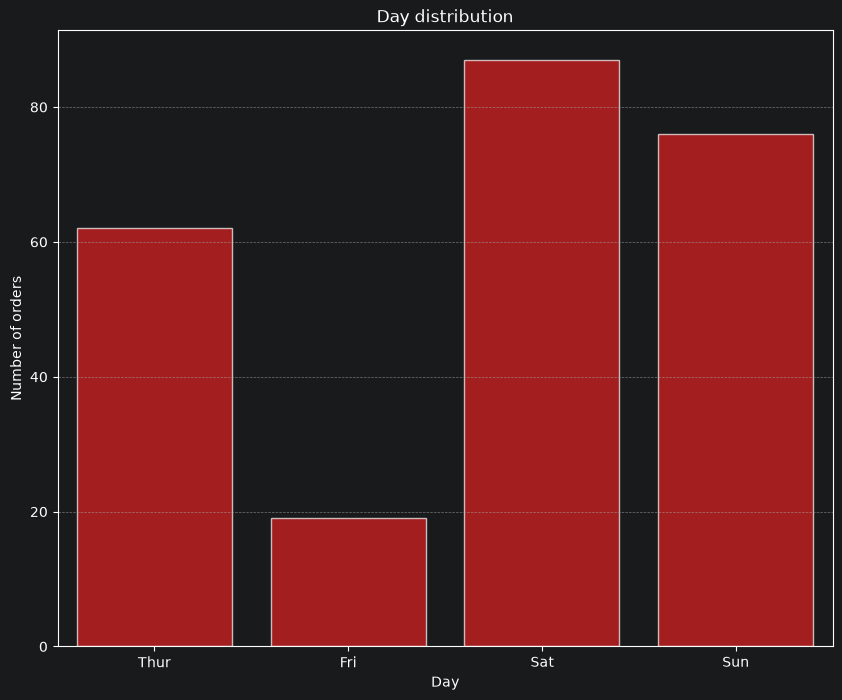

In [34]:
plt.figure(figsize=(10,8))

sns.countplot(
    data=df_tips,
    x="day",
    order=df_tips["day"].cat.categories,
    edgecolor = "white",
    color = "red",
    alpha = 0.7
)

plt.grid(axis="y", linestyle = "--", alpha = 0.6)
plt.title("Day distribution")
plt.xlabel("Day")
plt.ylabel("Number of orders")
plt.show()

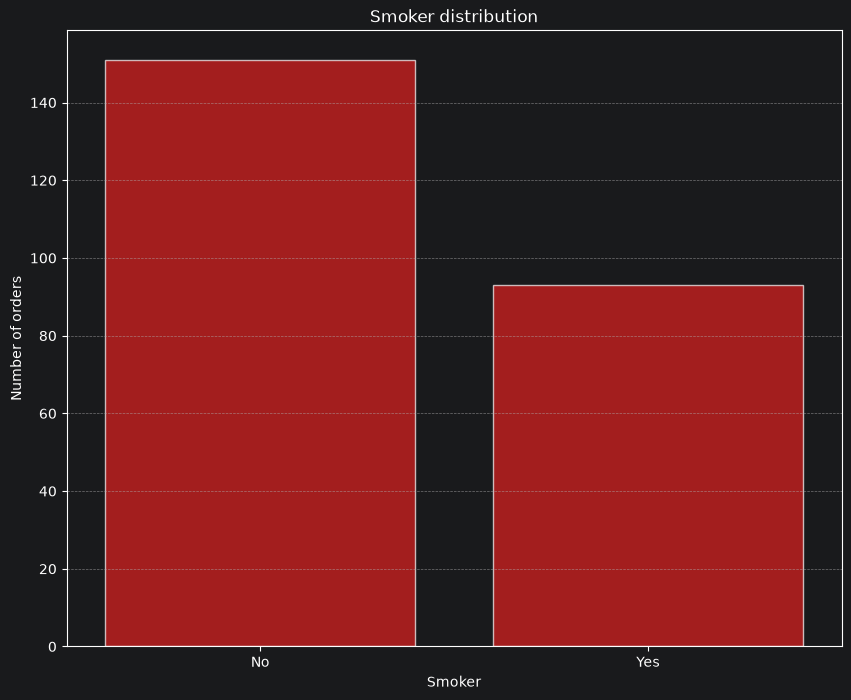

In [13]:
plt.figure(figsize=(10,8))

sns.countplot(
    data=df_tips,
    x="smoker",
    order=df_tips["smoker"].value_counts().index,
    edgecolor = "white",
    color="red",
    alpha = 0.7
)

plt.grid(axis="y", linestyle = "--", alpha = 0.6)
plt.title("Smoker distribution")
plt.xlabel("Smoker")
plt.ylabel("Number of orders")
plt.show()

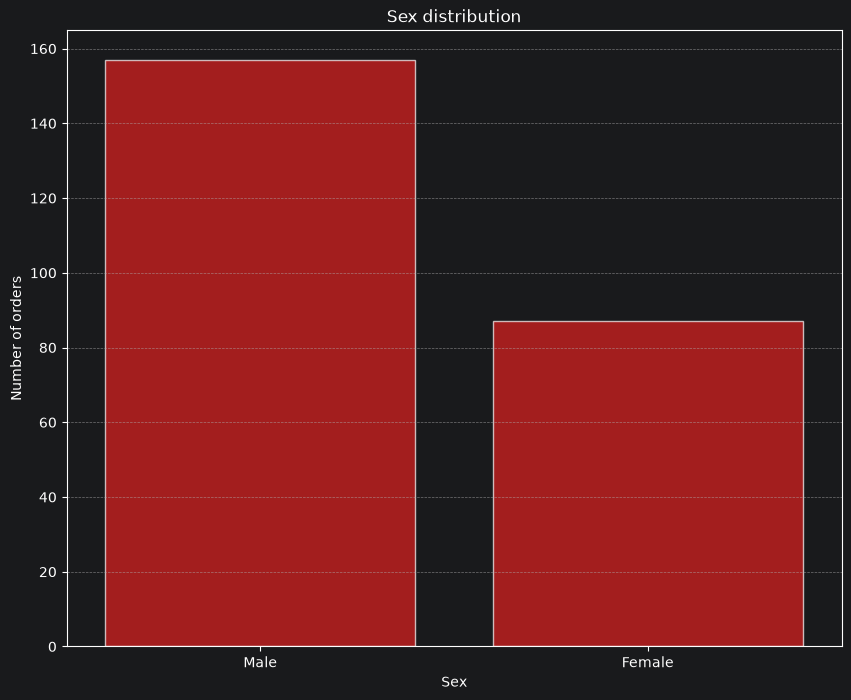

In [14]:
plt.figure(figsize=(10,8))

sns.countplot(
    data=df_tips,
    x="sex",
    order=df_tips["sex"].value_counts().index,
    edgecolor="white",
    color="red",
    alpha = 0.7
)

plt.grid(axis="y", linestyle = "--", alpha = 0.6)
plt.title("Sex distribution")
plt.xlabel("Sex")
plt.ylabel("Number of orders")
plt.show()

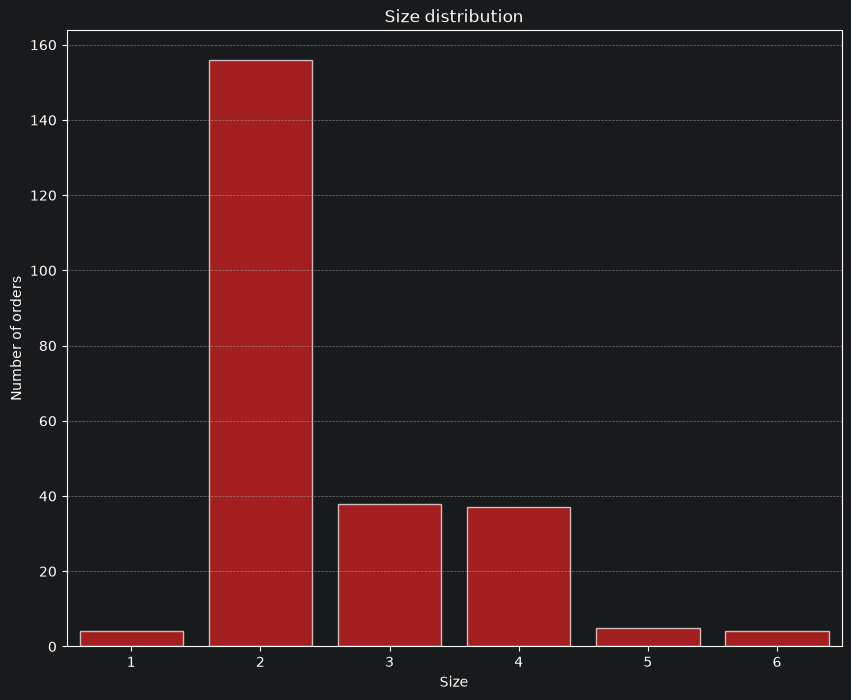

In [15]:
plt.figure(figsize=(10,8))

sns.countplot(
    data=df_tips,
    x="size",
    order=sorted(df_tips["size"].value_counts().index),
    edgecolor="white",
    color="red",
    alpha=0.7
)

plt.grid(axis="y", linestyle = "--", alpha = 0.6)
plt.title("Size distribution")
plt.xlabel("Size")
plt.ylabel("Number of orders")
plt.show()

## 3. Research questions

### Q1: Do sex and smoking status matter?

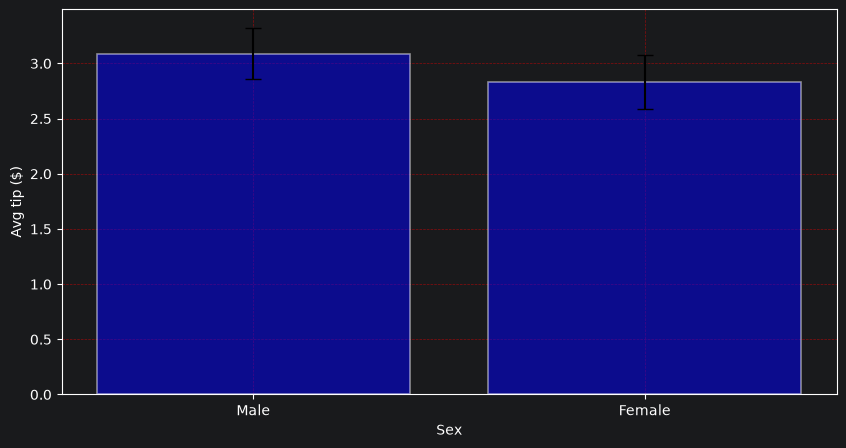

In [16]:
stats = df_tips.groupby("sex", observed=True)["tip"].agg(["mean", "std", "count"])
ci95 = 1.96 * stats["std"] / np.sqrt(stats["count"])

plt.figure(figsize=(10, 5))
plt.bar(
    stats.index.astype(str),
    stats["mean"],
    yerr=ci95,
    capsize=6,
    color="blue",
    edgecolor="white",
    linewidth=1.2,
    zorder=2,
    error_kw={"zorder": 4, "elinewidth": 1.5},
    alpha = 0.5
)
plt.grid(True, linestyle="--", alpha=0.5, color="red", zorder=0)
plt.xlabel("Sex")
plt.ylabel("Avg tip ($)")
plt.show()

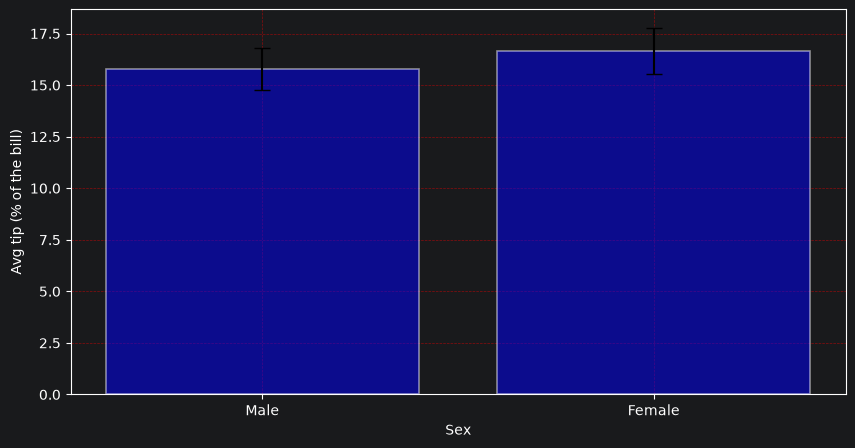

In [17]:
stats = df_tips.groupby("sex", observed=True)["tip_pct"].agg(["mean", "std", "count"])
ci95 = 1.96 * stats["std"] / np.sqrt(stats["count"])

plt.figure(figsize=(10, 5))
plt.bar(
    stats.index.astype(str),
    stats["mean"],
    yerr=ci95,
    capsize=6,
    color="blue",
    edgecolor="white",
    linewidth=1.2,
    zorder=2,
    error_kw={"zorder": 4, "elinewidth": 1.5},
    alpha=0.5
)
plt.grid(True, linestyle="--", alpha=0.5, color="red", zorder=0)
plt.xlabel("Sex")
plt.ylabel("Avg tip (% of the bill)")
plt.show()

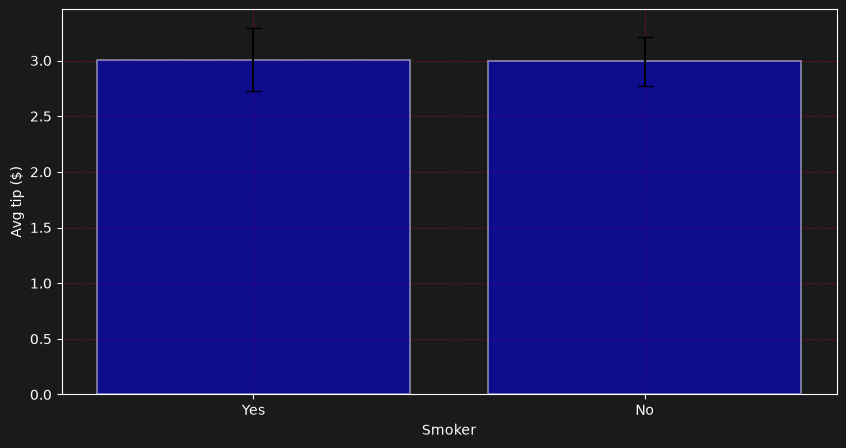

In [18]:
stats = df_tips.groupby("smoker", observed=True)["tip"].agg(["mean", "std", "count"])
ci95 = 1.96 * stats["std"] / np.sqrt(stats["count"])

plt.figure(figsize=(10, 5))
plt.bar(
    stats.index.astype(str),
    stats["mean"],
    yerr=ci95,
    capsize=6,
    color="blue",
    edgecolor="white",
    linewidth=1.2,
    zorder=2,
    error_kw={"zorder": 4, "elinewidth": 1.5},
    alpha = 0.5
)
plt.grid(True, linestyle="--", alpha=0.5, color="red", zorder=0)
plt.xlabel("Smoker")
plt.ylabel("Avg tip ($)")
plt.show()

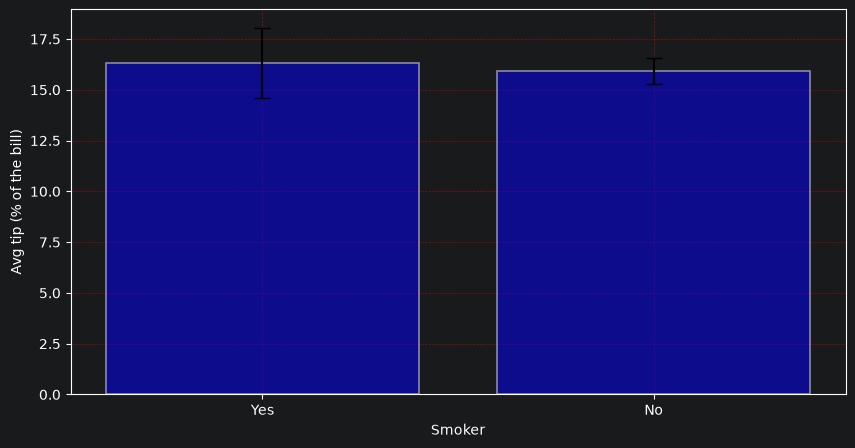

In [19]:
stats = df_tips.groupby("smoker", observed=True)["tip_pct"].agg(["mean", "std", "count"])
ci95 = 1.96 * stats["std"] / np.sqrt(stats["count"])

plt.figure(figsize=(10, 5))
plt.bar(
    stats.index.astype(str),
    stats["mean"],
    yerr=ci95,
    capsize=6,
    color="blue",
    edgecolor="white",
    linewidth=1.2,
    zorder=2,
    error_kw={"zorder": 4, "elinewidth": 1.5},
    alpha=0.5
)
plt.grid(True, linestyle="--", alpha=0.5, color="red", zorder=0)
plt.xlabel("Smoker")
plt.ylabel("Avg tip (% of the bill)")
plt.show()

**Observed**
Men leave slightly higher tips in dollars, while women's tip percentage looks slightly higher. The confidence intervals overlap, so both differences are small compared to the noise. Smoking status shows no visible difference in either dollars or percent.

**Hypothesis**

Men might have higher bills on average, and tip % falls as the bill grows, so this could partly explain the gap.

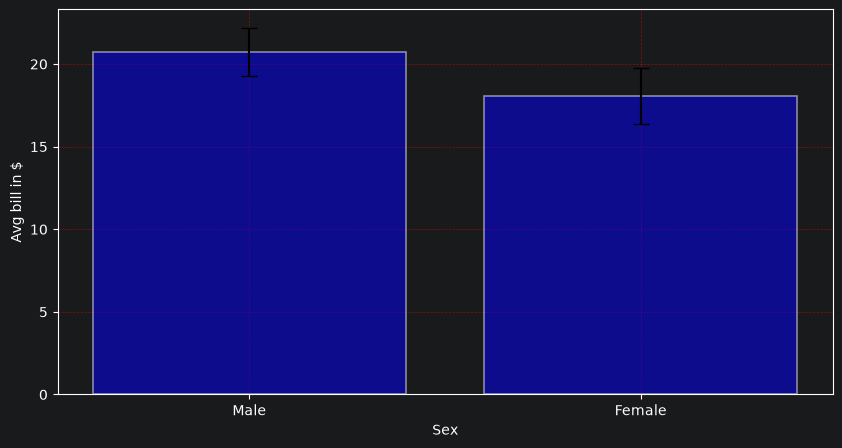

In [20]:
stats = df_tips.groupby("sex", observed=True)["total_bill"].agg(["mean", "std", "count"])
ci95 = 1.96 * stats["std"] / np.sqrt(stats["count"])

plt.figure(figsize=(10, 5))
plt.bar(
    stats.index.astype(str),
    stats["mean"],
    yerr=ci95,
    capsize=6,
    color="blue",
    edgecolor="white",
    linewidth=1.2,
    zorder=2,
    error_kw={"zorder": 4, "elinewidth": 1.5},
    alpha=0.5
)
plt.grid(True, linestyle="--", alpha=0.5, color="red", zorder=0)
plt.xlabel("Sex")
plt.ylabel("Avg bill in $")
plt.show()

In [21]:
df_tips["bill_per_person"] = df_tips["total_bill"] / df_tips["size"]

size_band = df_tips["size"].clip(upper=4)
pd.crosstab(size_band, df_tips["sex"])

sex,Male,Female
size,,
1,1,3
2,98,58
3,24,14
4,34,12


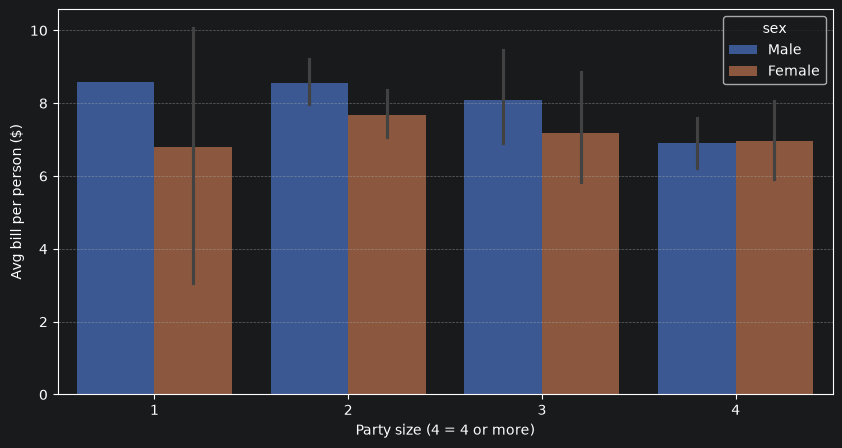

In [22]:
plt.figure(figsize=(10, 5))
sns.barplot(data=df_tips.assign(size_band=size_band),
            x="size_band", y="bill_per_person", hue="sex",
            errorbar=("ci", 95), alpha=0.7)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.xlabel("Party size (4 = 4 or more)")
plt.ylabel("Avg bill per person ($)")
plt.show()

In [23]:
df_tips.groupby("sex", observed=True)[["total_bill", "bill_per_person"]].mean().round(2)

,total_bill,bill_per_person
sex,,
Male,20.74,8.12
Female,18.06,7.46


**Follow-up:**

Men's average table bill is higher, although the confidence intervals slightly overlap, so the difference is moderate. The bill per person is also a bit higher for men, with overlapping intervals. Tip % falls as the bill grows. Party size 1 has only 4 orders and is ignored.

In [24]:
print(df_tips["bill_per_person"].corr(df_tips["tip_pct"], method="spearman"))

-0.24454882381182635


In [25]:
bill_band = pd.qcut(df_tips["total_bill"], 4)
df_tips.groupby([bill_band, "sex"], observed=True)["tip_pct"].agg(["median", "count"])

median  count
total_bill       sex                     
(3.069, 13.348]  Male    16.650438     33
                 Female  17.433897     28
(13.348, 17.795] Male    14.803849     35
                 Female  17.854092     26
(17.795, 24.127] Male    15.932500     46
                 Female  15.267176     15
(24.127, 50.81]  Male    12.138869     43
                 Female  14.430569     18

**Q1 Answer**

Sex has no clear effect on how generously people tip. Men leave slightly more in dollars, most likely because their bills tend to be higher. Smoking status has no visible effect.

### Q2: How does the tip depend on the bill?

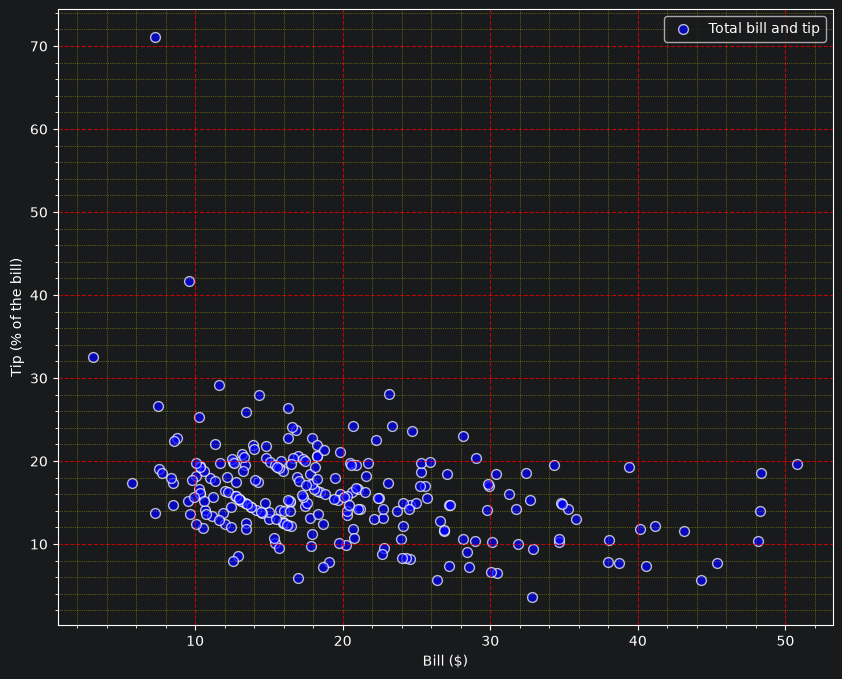

In [26]:
plt.figure(figsize=(10, 8))

plt.scatter(
    df_tips["total_bill"],
    df_tips["tip_pct"],
    marker="o",
    s=50,
    edgecolor="white",
    alpha=0.7,
    color="blue",
    label="Total bill and tip"
)

plt.minorticks_on()
plt.grid(which='major', linestyle='--', linewidth=0.8, alpha=0.7, color='red', zorder=0)
plt.grid(which='minor', linestyle=':', linewidth=0.5, alpha=0.55, color='yellow', zorder=0)

plt.xlabel("Bill ($)")
plt.ylabel("Tip (% of the bill)")
plt.legend()
plt.show()

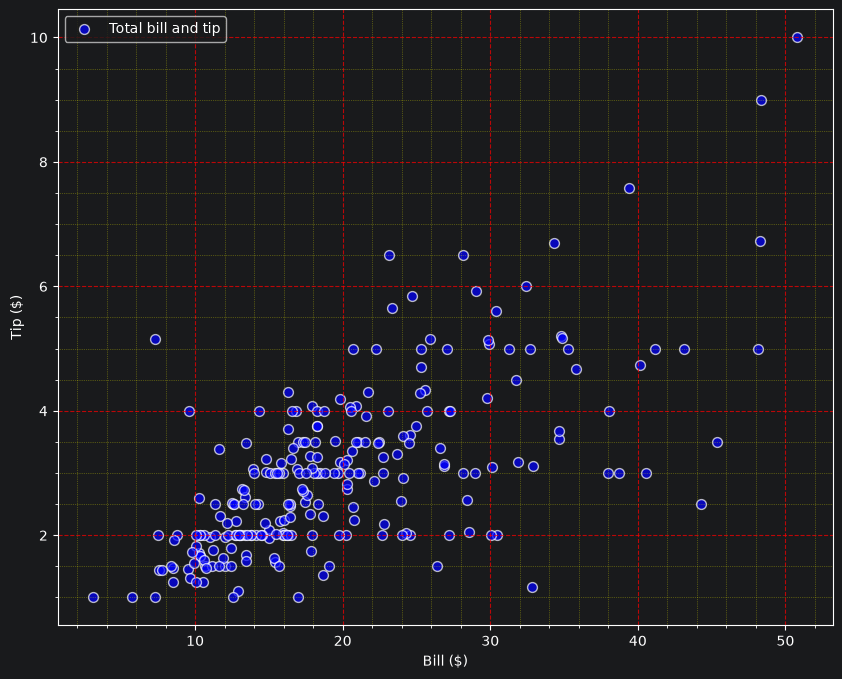

In [27]:
plt.figure(figsize=(10,8))

plt.scatter(
    df_tips["total_bill"],
    df_tips["tip"],
    marker="o",
    s=50,
    edgecolor="white",
    color="blue",
    alpha=0.7,
    label="Total bill and tip"
)

plt.minorticks_on()
plt.grid(which="major", linestyle="--", linewidth=0.8, alpha=0.7, color="red", zorder=0)
plt.grid(which="minor", linestyle=":", linewidth=0.5, alpha=0.5, color="yellow", zorder=0)

plt.xlabel("Bill ($)")
plt.ylabel("Tip ($)")
plt.legend()
plt.show()

In [28]:
print(df_tips["total_bill"].corr(df_tips["tip_pct"], method="spearman"))

bins = pd.qcut(df_tips["total_bill"], 4)
print(df_tips.groupby(bins, observed=True)["tip_pct"].agg(["median", "count"]))

-0.32068002709668625
                     median  count
total_bill                        
(3.069, 13.348]   17.370892     61
(13.348, 17.795]  15.365704     61
(17.795, 24.127]  15.687251     61
(24.127, 50.81]   13.942407     61


### Q3: Does the day or time matter?

In [29]:
pd.crosstab(df_tips["day"], df_tips["time"], margins=True)

time,Lunch,Dinner,All
day,,,
Thur,61,1,62
Fri,7,12,19
Sat,0,87,87
Sun,0,76,76
All,68,176,244


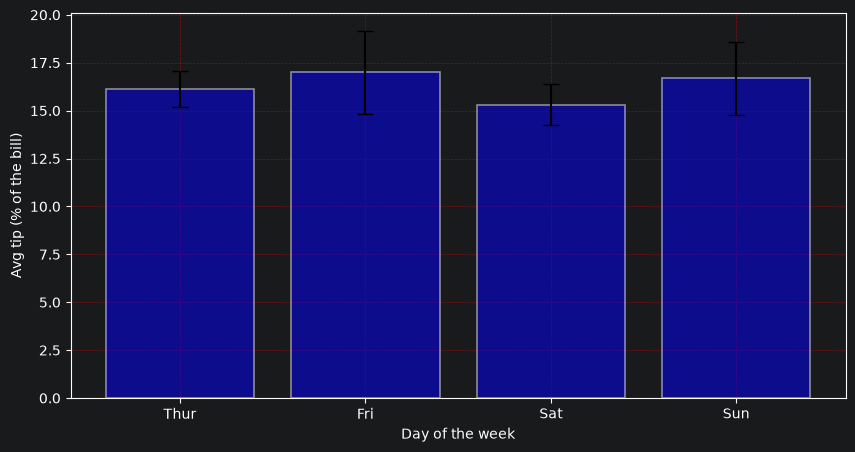

In [30]:
stats = df_tips.groupby("day", observed=True)["tip_pct"].agg(["mean", "std", "count"])
ci95 = 1.96 * stats["std"] / np.sqrt(stats["count"])

plt.figure(figsize=(10, 5))
plt.bar(
    stats.index.astype(str),
    stats["mean"],
    yerr=ci95,
    capsize=6,
    color="blue",
    edgecolor="white",
    linewidth=1.2,
    zorder=2,
    error_kw={"zorder": 4, "elinewidth": 1.5},
    alpha=0.5,
)
plt.grid(True, linestyle="--", alpha=0.5, color="red", zorder=0)
plt.xlabel("Day of the week")
plt.ylabel("Avg tip (% of the bill)")
plt.show()

## 4. EDA conclusions

## 5. Preparing data for modelling

In [31]:
df_tips_enc = (
    df_tips.assign(
        is_male=lambda d: d["sex"].map({"Female": 0, "Male": 1}).astype(int),
        is_smoker=lambda d: d["smoker"].map({"No": 0, "Yes": 1}).astype(int),
        is_dinner=lambda d: d["time"].map({"Lunch": 0, "Dinner": 1}).astype(int),
    )

    .pipe(pd.get_dummies, columns=["day"], prefix="day", dtype=int)

    .drop(columns=["sex", "smoker", "time"])
)

df_tips_enc.head()

,total_bill,tip,size,tip_pct,bill_per_person,is_male,is_smoker,is_dinner,day_Thur,day_Fri,day_Sat,day_Sun
0,16.99,1.01,2,5.944673,8.495000,0,0,1,0,0,0,1
1,10.34,1.66,3,16.054159,3.446667,1,0,1,0,0,0,1
2,21.01,3.50,3,16.658734,7.003333,1,0,1,0,0,0,1
3,23.68,3.31,2,13.978041,11.840000,1,0,1,0,0,0,1
4,24.59,3.61,4,14.680765,6.147500,0,0,1,0,0,0,1


### Pearson vs Spearman

In [32]:
pearson = df_tips_enc.corr(method="pearson")
spearman = df_tips_enc.corr(method="spearman")

(pearson - spearman).abs().round(2)

,total_bill,tip,size,tip_pct,bill_per_person,is_male,is_smoker,is_dinner,day_Thur,day_Fri,day_Sat,day_Sun
total_bill,0.00,0.00,0.01,0.02,0.01,0.00,0.02,0.02,0.01,0.01,0.00,0.02
tip,0.00,0.00,0.02,0.05,0.05,0.03,0.01,0.02,0.02,0.02,0.05,0.06
size,0.01,0.02,0.00,0.01,0.01,0.01,0.00,0.06,0.06,0.01,0.04,0.02
tip_pct,0.02,0.05,0.01,0.00,0.07,0.03,0.07,0.04,0.03,0.01,0.02,0.05
bill_per_person,0.01,0.05,0.01,0.07,0.00,0.02,0.07,0.02,0.02,0.00,0.00,0.02
is_male,0.00,0.03,0.01,0.03,0.02,0.00,0.00,0.00,0.00,0.00,0.00,0.00
is_smoker,0.02,0.01,0.00,0.07,0.07,0.00,0.00,0.00,0.00,0.00,0.00,0.00
is_dinner,0.02,0.02,0.06,0.04,0.02,0.00,0.00,0.00,0.00,0.00,0.00,0.00
day_Thur,0.01,0.02,0.06,0.03,0.02,0.00,0.00,0.00,0.00,0.00,0.00,0.00
day_Fri,0.01,0.02,0.01,0.01,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


### Correlation heatmap

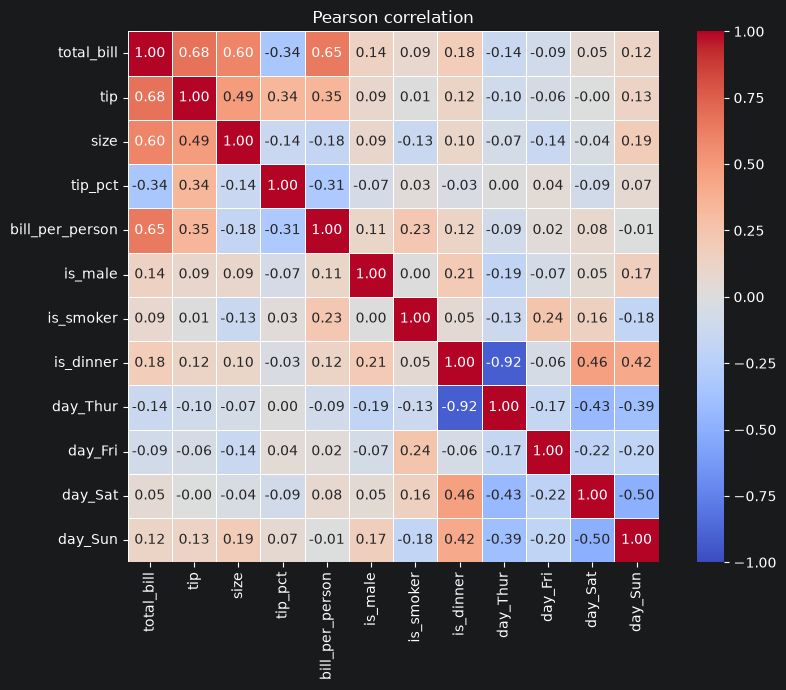

In [33]:
corr = df_tips_enc.corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    linewidths=0.5,
    square=True,
)
ax.set_title("Pearson correlation")
fig.tight_layout()
plt.show()